# Edge detection

In this lab exercise, you will look at applying edge detectors to images and comparing two different methods. You will also learn how to write a function in Python and evaluate the difference when using an approximation for the calculation of a parameter.

At this stage, we will assume that you are able to use Python, and understand its basic use. **You are asked to write a short (no more than 2 pages) report of your work**, answering specific questions, and showing example images. This work is not assessed (it will not count towards your module mark) but you will get formative feedback.

### Introduction

First we will cover some basics regarding Python and Image Manipulation.

The first step is importing the required packages. In this assignment we will be using [scikit-image](https://scikit-image.org/), [MatPlotLib](https://matplotlib.org/) and [Numpy](https://numpy.org/). We have also provided helper functions for displaying the images inline (utils.py). Check that your environment is configured correctly by running the section below. 

In [5]:
# Imports
import skimage
import scipy
from matplotlib import pyplot as plt
import numpy as np
from utils import show_binary_image
from scipy.signal import convolve2d
import skimage.io

In order to load images we use the [imread](https://scikit-image.org/docs/stable/user_guide/getting_started.html) function which is part of scikit-image. Images can be displayed using the show_rgb_image helper function. Read through this function to understand how it works. We can also see the raw image data by printing the variable using ```print```. As can be seen, by default in Skimage image pixels are represented as bytes with a range of 0-255. 

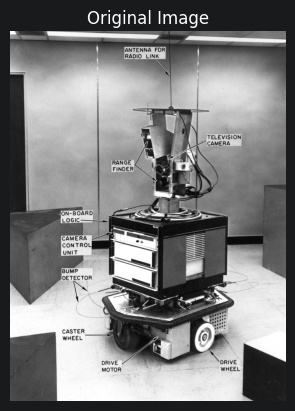

Shakey raw values [[254 254 254 ... 131 122 122]
 [254 254 254 ... 120 113 113]
 [254 254 254 ... 121 113 113]
 ...
 [ 83  81  78 ...  39  39  39]
 [ 83  81  78 ...  41  41  41]
 [ 83  81  78 ...  43  43  43]]


In [6]:

# Read image
shakey = skimage.io.imread('shakey.jpg')[:,:,0] #Extract the Green Channel

# Display the image
plt.imshow(shakey,cmap="gray")
plt.title("Original Image")
plt.axis('off')
plt.show()

print("Shakey raw values", shakey)

In scikit we perform convolution using the convolve2d function. Kernels can be defined as numpy arrays as seen below. A detailed guide to this function can be found here: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.convolve2d.html

In [7]:
sobel_x = np.array(
    [[1,0,-1],
     [2,0,-2],
     [1,0,-1]])

sobel_y = np.array(
    [[1,2,1],
     [0,0,0],
     [-1,-2,-1]])

print(sobel_y)

[[ 1  2  1]
 [ 0  0  0]
 [-1 -2 -1]]


Boolean Thesholded Values:
[[ True  True False ... False  True  True]
 [ True  True False ... False  True  True]
 [ True  True False ... False  True  True]
 ...
 [ True  True False ... False  True  True]
 [ True  True False ... False  True  True]
 [ True  True False ... False False False]]
Boolean Thesholded Image:


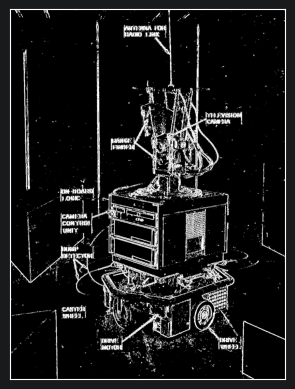

In [8]:
# Applying a filter
# We convert the output type to floats in order to preserve negative gradients
# We can also threshold the image using the > operator
threshold_shakey_sobel_x = abs(scipy.signal.convolve2d(shakey, sobel_x))>50

print("Boolean Thesholded Values:")
print(threshold_shakey_sobel_x)

# Here we use the binary helper function as our image is now binary
print("Boolean Thesholded Image:")
show_binary_image(threshold_shakey_sobel_x)


# Task1

Combine the two resulting arrays (shakey_sobel_x and shakey_sobel_y) to compute magnitude. To do this you will have to make your own function, such that:

```m = magnitude(x,y)```

Now display the resulting image using

```show_rgb_image(m)```

You can also display this edge image after thresholding it,

```show_binary_image(m>40)```

Create several of these with different thresholds.

**QUESTION 1: What do you notice regarding the effect of changing the threshold? State both your observations and the reasons for the observations. Show your code, results and answer in the report.**

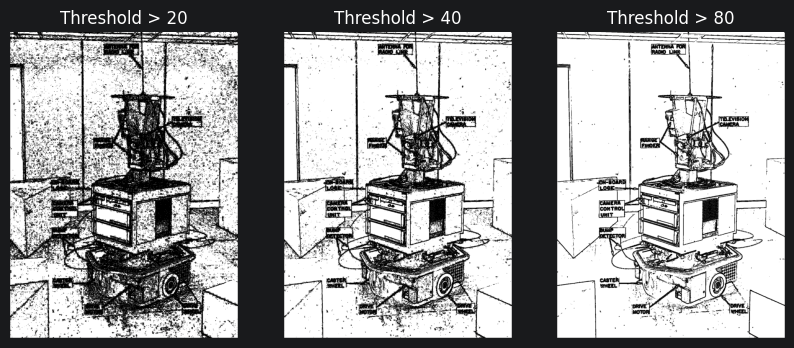

'Question 1 (Threshold Effect): Increasing the threshold removes background noise caused by minor intensity fluctuations, but setting it too high deletes low-contrast, genuine object edges.'

In [22]:
# Complete Task 1 here
shakey_sobel_x = convolve2d(shakey, sobel_x, mode="same")
shakey_sobel_y = convolve2d(shakey, sobel_y, mode="same")

# Function to compute magnitude
def magnitude(x, y):
    return np.sqrt(x**2 + y**2)

slobel_magnitude= magnitude(shakey_sobel_x ,shakey_sobel_y)
# Compare thresholds
#1- Making a figure that contains different subplots
plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(slobel_magnitude > 20, cmap="binary")
plt.axis("off")
plt.title("Threshold > 20")

plt.subplot(1, 3, 2)
plt.imshow(slobel_magnitude > 40, cmap="binary")
plt.axis("off")
plt.title("Threshold > 40")

plt.subplot(1, 3, 3)
plt.imshow(slobel_magnitude > 80, cmap="binary")
plt.title("Threshold > 80")
plt.axis("off")
plt.show()

'''Question 1 (Threshold Effect): Increasing the threshold removes background noise caused by minor intensity fluctuations, but setting it too high deletes low-contrast, genuine object edges.'''

# Task 2

Repeat your previous exercise, with the Roberts operator.

The Roberts operator is defined as:

$$
Gx = 
\begin{matrix}
+1 & 0 \\
0 & -1 
\end{matrix}
$$

$$
Gy = 
\begin{matrix}
0 & +1 \\
-1 & 0 
\end{matrix}
$$

**QUESTION 2: What do you notice regarding the difference between Sobel and Roberts? State both your observations and the reasons for the observations.**

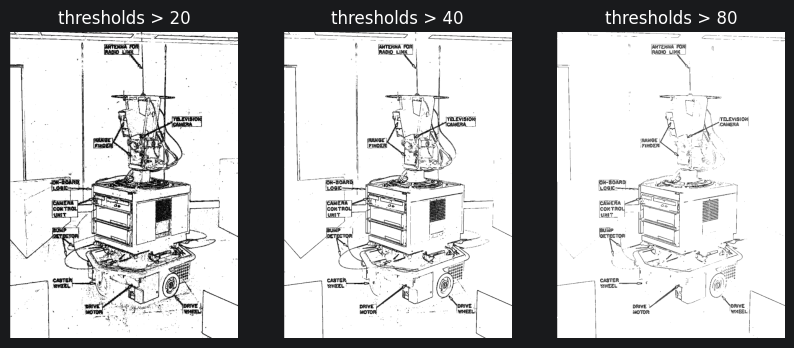

'Question 2: Roberts produces thinner, sharper lines but is noisy and fragmented because its 2X2 window lacks smoothing.'

In [25]:
# Complete Task 2 here
roberts_x= np.array( [ [1,0], [0,-1] ])

roberts_y=  np.array( [ [0,1], [-1,0] ])

shakey_roberts_x= convolve2d(shakey, roberts_x, mode="same")
shakey_roberts_y= convolve2d(shakey, roberts_y, mode="same")

# Function to compute magnitude
def magnitude(x, y):
    return np.sqrt(x**2 + y**2)

# Function to compute magnitude
robert_magnitude= magnitude(shakey_roberts_x ,shakey_roberts_y)

# Visualizing Roberts thresholds
plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(robert_magnitude > 20, cmap="binary")
plt.title("thresholds > 20")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robert_magnitude > 40, cmap="binary")
plt.title("thresholds > 40")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robert_magnitude > 80, cmap="binary")
plt.title("thresholds > 80")
plt.axis("off")
plt.show()

'''Question 2: Roberts produces thinner, sharper lines but is noisy and fragmented because its 2X2 window lacks smoothing.'''

# Task 3

You now need to write a new function, that rather than taking the magnitude of the gradients, it takes the absolute value of |Gx|+|Gy|. This is an approximation to the magnitude.

**QUESTION 3: What do you notice regarding the difference between magnitude and absolute when calculating the edge? State both your observations and the reasons for the observations.**

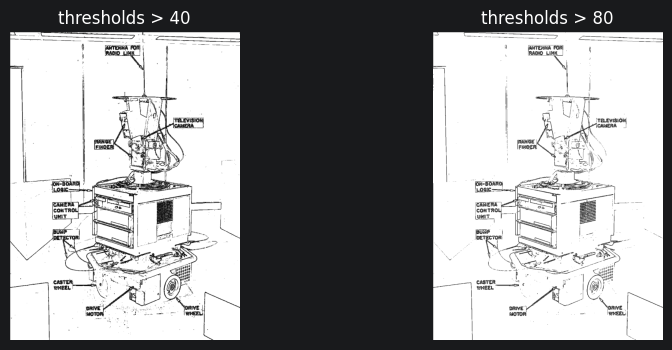

In [24]:
# Complete Task 3 here
roberts_x= np.array( [ [1,0], [0,-1] ])


roberts_y=  np.array( [ [0,1], [-1,0] ])

shakey_roberts_x= convolve2d(shakey, roberts_x, mode="same")
shakey_roberts_y= convolve2d(shakey, roberts_y, mode="same")

# Function to compute magnitude
def magnitude(x, y):
    return np.abs(x) + np.abs(y)
absolute_magnitude= magnitude(shakey_roberts_x ,shakey_roberts_y)

# Visualizing Roberts thresholds
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(absolute_magnitude > 40, cmap="binary")
plt.title("thresholds > 40")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(absolute_magnitude > 80, cmap="binary")
plt.title("thresholds > 80")
plt.axis("off")

plt.show()
'''Question 3:diagonal lines appear slightly thicker. '''
